In [283]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt


In [284]:
pd.set_option("display.max_rows",None)


In [285]:
pd.set_option("display.max_rows",10)

### DataSet Import

In [286]:
data = pd.read_csv("Dataset/gurgaon_properties_cleaned.csv")

In [287]:
dt = data.copy()

In [288]:
dt.columns

Index(['property_name', 'property_type', 'society', 'sector', 'area', 'price',
       'price_per_sqft', 'Plot area', 'Super Built Up area', 'Built Up area',
       'Carpet area', 'bedRoom', 'bathroom', 'balcony', 'address', 'floorNum',
       'facing', 'agePossession', 'description', 'rating', 'Study Room',
       'Pooja Room', 'Servant Room', 'Store Room', 'Others', 'Dining Table',
       'Curtains', 'Sofa', 'Water Purifier', 'Chimney', 'Geyser', 'Wardrobe',
       'Fridge', 'Microwave', 'Stove', 'TV', 'Washing Machine', 'Bed', 'AC',
       'Light', 'Fan', 'Exhaust Fan', 'Modular Kitchen', 'furnishing_type',
       'luxury score'],
      dtype='object')

### area

C:\Users\91959\AppData\Local\Temp\ipykernel_248\2611761619.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dt['area'])


<Axes: xlabel='area', ylabel='Density'>

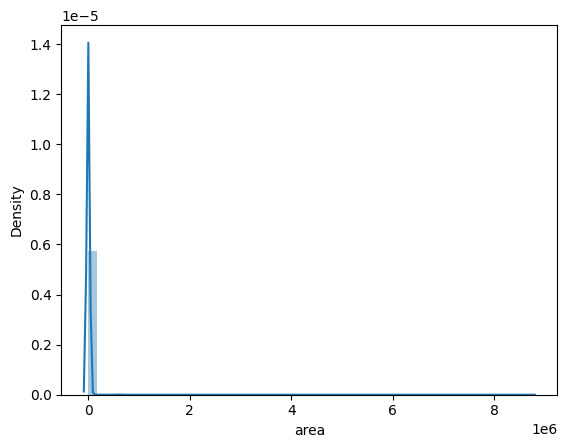

In [289]:
sns.distplot(dt['area'])

In [290]:
dt['area'] = round(dt['area'],2)

### price

C:\Users\91959\AppData\Local\Temp\ipykernel_248\577126445.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dt['price'])


<Axes: xlabel='price', ylabel='Density'>

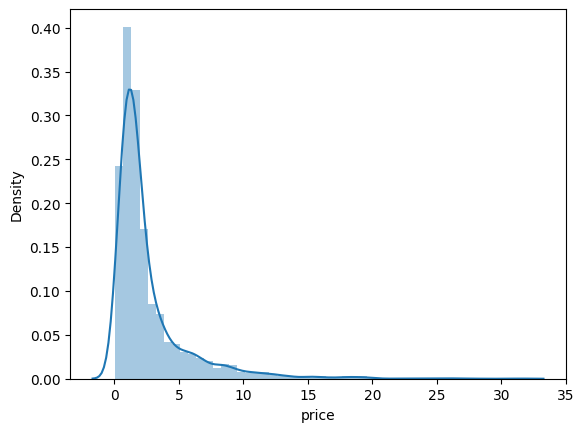

In [291]:
sns.distplot(dt['price'])

C:\Users\91959\AppData\Local\Temp\ipykernel_248\577126445.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dt['price'])


<Axes: xlabel='price', ylabel='Density'>

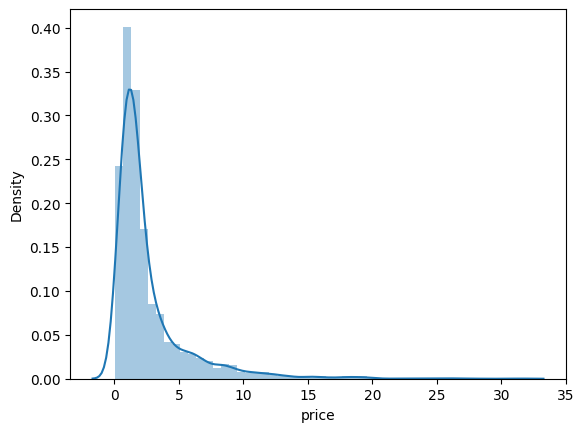

In [292]:
sns.distplot(dt['price'])

In [293]:
#outlier filtering
q1 = dt['price'].quantile(0.25)
q3 = dt['price'].quantile(0.75)
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
outlier = dt[(dt['price']<l_bound) | (dt['price']>u_bound)]
print(outlier.shape)
print(outlier['price'].describe())

(394, 45)
count    394.000000
mean       9.755810
std        4.035179
min        6.000000
25%        6.950000
50%        8.500000
75%       11.000000
max       31.500000
Name: price, dtype: float64


In [294]:
# outlier.to_csv('read-price-outlier-data.csv')

In [295]:
filtered_outlier = pd.DataFrame(columns=outlier.columns)
for i in range(outlier.shape[0]):
    x = outlier.iloc[[i]]
    price = int(x['price']*10000000)
    price_per = int(x['price_per_sqft'])
    plot = int(x['Plot area'])
    carpet = int(x['Carpet area'])
    built_up = int(x['Built Up area'])
    super_built_up = int(x['Super Built Up area'])
    a = abs((plot*price_per) - price)
    b = abs((carpet*price_per)-price)
    c = abs((built_up*price_per)-price)
    d = abs((super_built_up*price_per)-price)
    if  (a<=5000) or (b<=5000) or (c<=5000) or (d<=5000):
         continue
    else:
        filtered_outlier = pd.concat([filtered_outlier,x])
print(filtered_outlier.shape)
print(dt.shape,dt.shape,filtered_outlier.shape)
#somehow reduced -removing the genuine high property prices

C:\Users\91959\AppData\Local\Temp\ipykernel_248\1324268011.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  price = int(x['price']*10000000)
C:\Users\91959\AppData\Local\Temp\ipykernel_248\1324268011.py:5: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  price_per = int(x['price_per_sqft'])
C:\Users\91959\AppData\Local\Temp\ipykernel_248\1324268011.py:6: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  plot = int(x['Plot area'])
C:\Users\91959\AppData\Local\Temp\ipykernel_248\1324268011.py:7: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  carpet = int(x['Carpet area'])
C:\Users\91959\AppData\Local\Temp\ipykernel_248\

(215, 45)
(3693, 45) (3693, 45) (215, 45)


C:\Users\91959\AppData\Local\Temp\ipykernel_248\1982801920.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dt['price'],color='lightgreen')
C:\Users\91959\AppData\Local\Temp\ipykernel_248\1982801920.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_dt['price'],color='lightgreen')


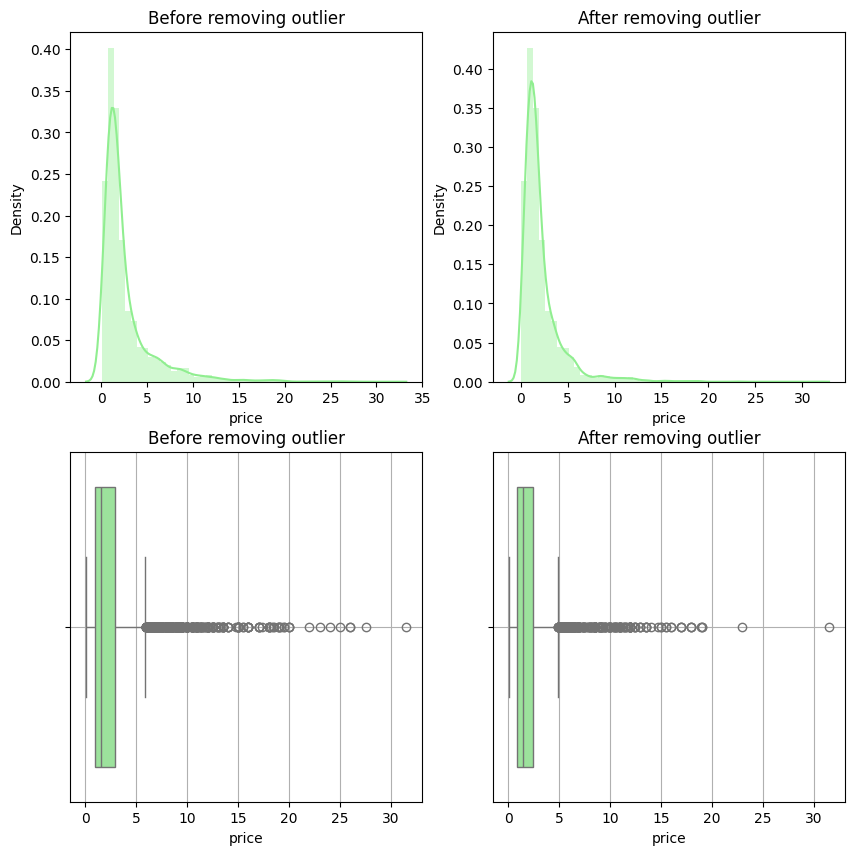

In [296]:
new_dt = dt.iloc[~dt.index.isin(filtered_outlier.index)]

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
sns.distplot(dt['price'],color='lightgreen')
plt.title("Before removing outlier")

plt.subplot(2,2,2)
sns.distplot(new_dt['price'],color='lightgreen')
plt.title("After removing outlier")

plt.subplot(2,2,3)
sns.boxplot(x=dt['price'],color='lightgreen')
plt.grid()
plt.title("Before removing outlier")

plt.subplot(2,2,4)
sns.boxplot(x=new_dt['price'],color='lightgreen')
plt.grid()
plt.title("After removing outlier")

plt.show()


In [297]:
filtered_outlier.index , filtered_outlier.shape

(Index([  37,   58,   61,   67,  111,  125,  133,  147,  162,  172,
        ...
        3576, 3602, 3604, 3625, 3627, 3661, 3675, 3678, 3681, 3688],
       dtype='int64', length=215),
 (215, 45))

### price_per_sqft

C:\Users\91959\AppData\Local\Temp\ipykernel_248\3666348591.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(new_dt['price_per_sqft'])


<Axes: xlabel='price_per_sqft', ylabel='Density'>

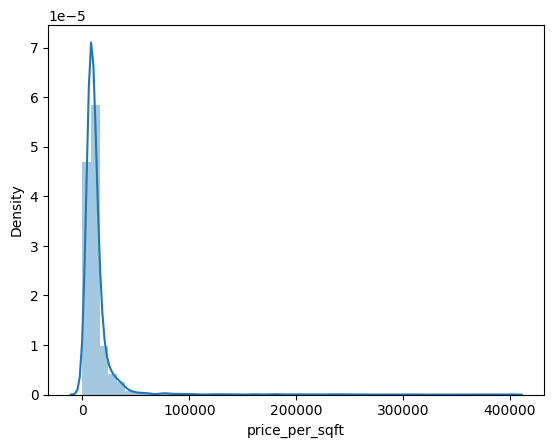

In [298]:
sns.distplot(new_dt['price_per_sqft'])

In [299]:
new_dt['price_per_sqft'].describe()

count      3478.000000
mean      13003.476711
std       18698.772474
min           2.000000
25%        6921.000000
50%        8973.000000
75%       13262.750000
max      400000.000000
Name: price_per_sqft, dtype: float64

In [300]:
#outlier filtering
q1 = new_dt['price_per_sqft'].quantile(0.25)
q3 = new_dt['price_per_sqft'].quantile(0.75)
iqr = q3-q1
l_bound = q1-1.5*iqr
u_bound = q3+1.5*iqr
outlier = new_dt[(new_dt['price_per_sqft']<l_bound) | (new_dt['price_per_sqft']>u_bound)]
print(outlier.shape)
print(outlier['price_per_sqft'].describe())

(303, 45)
count       303.000000
mean      49137.036304
std       49249.029383
min       22855.000000
25%       26329.000000
50%       32407.000000
75%       42124.000000
max      400000.000000
Name: price_per_sqft, dtype: float64


In [301]:
#outlier  selecting  price per sqft 
outlier['area'] = outlier['area'].apply(lambda x:x*9 if x<1000 else x)

C:\Users\91959\AppData\Local\Temp\ipykernel_248\2357736080.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  outlier['area'] = outlier['area'].apply(lambda x:x*9 if x<1000 else x)


In [302]:
filtered_outlier = pd.DataFrame(columns=new_dt.columns)
c=0
for i in range(outlier.shape[0]):
    #to get dataframe
    p = outlier.iloc[[i]]
    x = outlier.iloc[i]
    actual = (x['price']*10000000)/x['area']
    given =int(x['price_per_sqft'])
    if abs(actual-given)>1000:
        c+=1
        filtered_outlier = pd.concat([filtered_outlier,p])
print(filtered_outlier.shape,c)

(101, 45) 101


C:\Users\91959\AppData\Local\Temp\ipykernel_248\234345409.py:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  filtered_outlier = pd.concat([filtered_outlier,p])


In [303]:
clear_dt = new_dt.iloc[~new_dt.index.isin(filtered_outlier.index)]

In [304]:
clear_dt.shape

(3377, 45)

C:\Users\91959\AppData\Local\Temp\ipykernel_248\571732458.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dt['price_per_sqft'],color='lightgreen')
C:\Users\91959\AppData\Local\Temp\ipykernel_248\571732458.py:9: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(clear_dt['price_per_sqft'],color='l

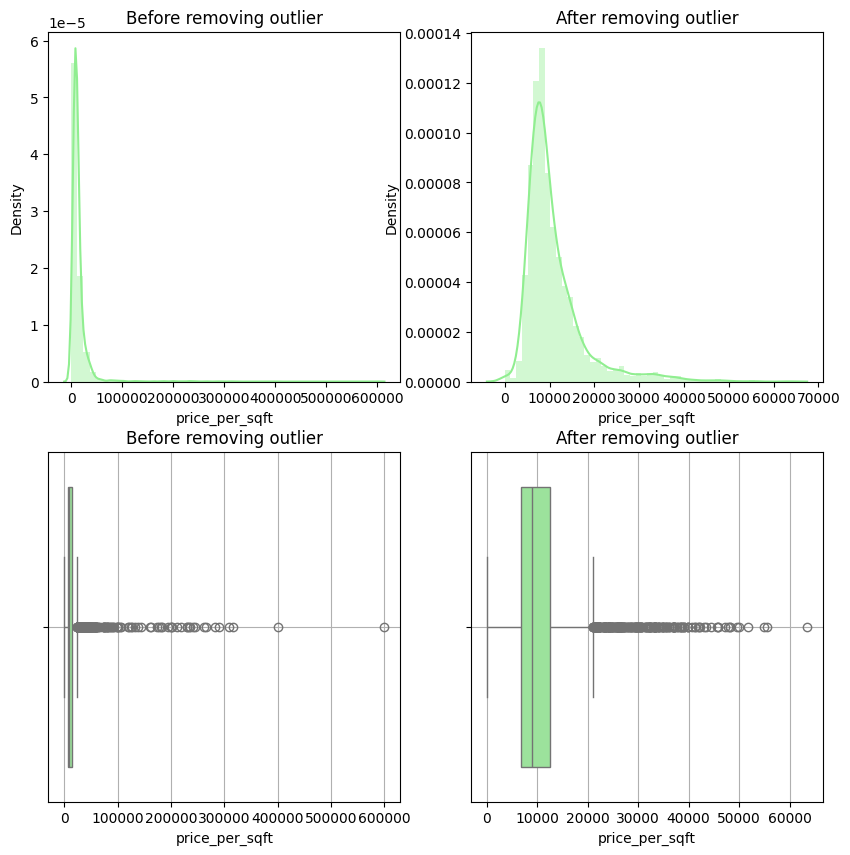

In [305]:
new_dt = dt.iloc[~dt.index.isin(filtered_outlier.index)]

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
sns.distplot(dt['price_per_sqft'],color='lightgreen')
plt.title("Before removing outlier")

plt.subplot(2,2,2)
sns.distplot(clear_dt['price_per_sqft'],color='lightgreen')
plt.title("After removing outlier")

plt.subplot(2,2,3)
sns.boxplot(x=dt['price_per_sqft'],color='lightgreen')
plt.grid()
plt.title("Before removing outlier")

plt.subplot(2,2,4)
sns.boxplot(x=clear_dt['price_per_sqft'],color='lightgreen')
plt.grid()
plt.title("After removing outlier")

plt.show()


### bedRoom

C:\Users\91959\AppData\Local\Temp\ipykernel_248\2047630233.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(clear_dt['bedRoom'])


<Axes: xlabel='bedRoom', ylabel='Density'>

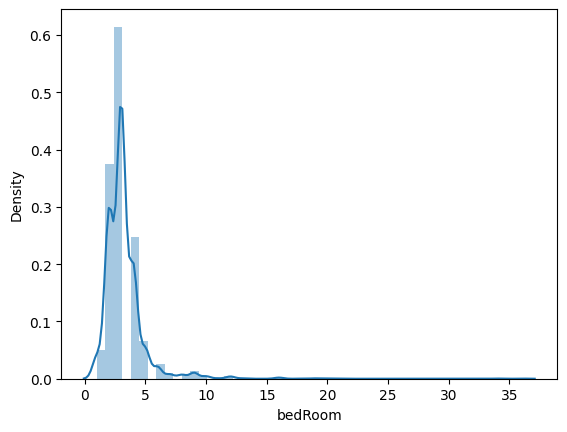

In [306]:
sns.distplot(clear_dt['bedRoom'])

In [307]:
clear_dt[(clear_dt['bedRoom']>10) & (clear_dt['price']<10)][['price','bedRoom']]

,price,bedRoom
90,2.00,11
197,5.00,21
499,7.49,12
786,8.00,12
1020,5.00,13
...,...,...
3355,8.49,12
3395,2.25,36
3523,9.25,12
3554,3.87,19


In [308]:
index = clear_dt[ (clear_dt['bedRoom']>10) & (clear_dt['price']<10)].index
index

Index([  90,  197,  499,  786, 1020, 1078, 1369, 1783, 1878, 1883, 1891, 2088,
       2191, 2211, 2254, 2970, 3046, 3355, 3395, 3523, 3554, 3565],
      dtype='int64')

In [309]:
next_dt = clear_dt.iloc[~clear_dt.index.isin(index)]


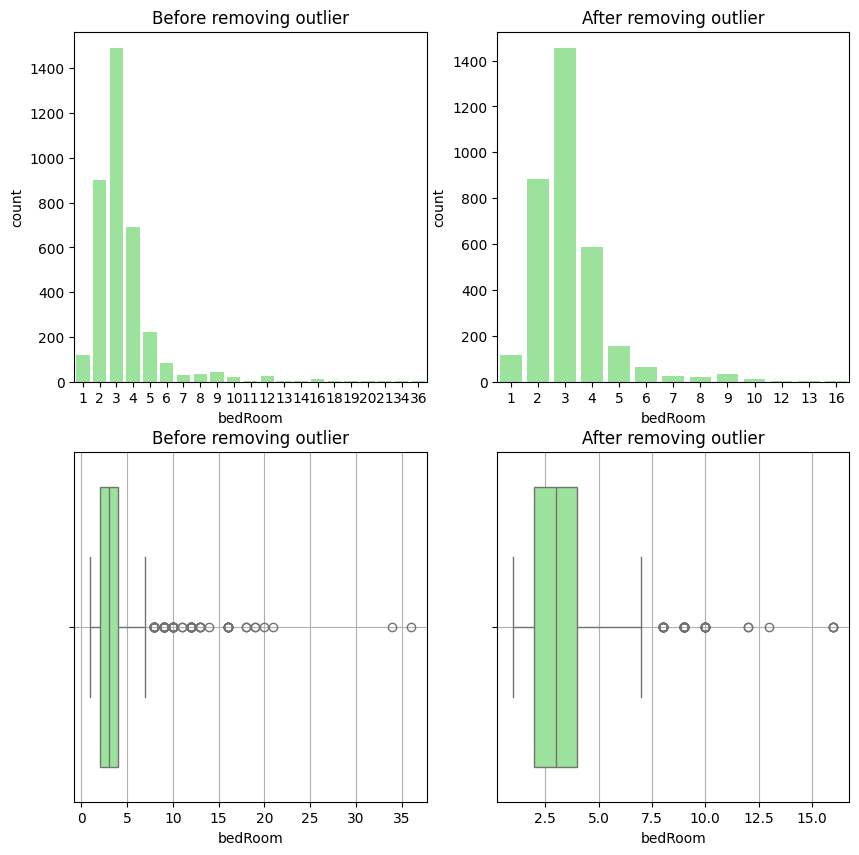

In [310]:
new_dt = dt.iloc[~dt.index.isin(filtered_outlier.index)]

plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
sns.barplot(dt['bedRoom'].value_counts(),color='lightgreen')
plt.title("Before removing outlier")

plt.subplot(2,2,2)
sns.barplot(next_dt['bedRoom'].value_counts(),color='lightgreen')
plt.title("After removing outlier")

plt.subplot(2,2,3)
sns.boxplot(x=dt['bedRoom'],color='lightgreen')
plt.grid()
plt.title("Before removing outlier")

plt.subplot(2,2,4)
sns.boxplot(x=next_dt['bedRoom'],color='lightgreen')
plt.grid()
plt.title("After removing outlier")

plt.show()


### balcony

<Axes: xlabel='balcony', ylabel='count'>

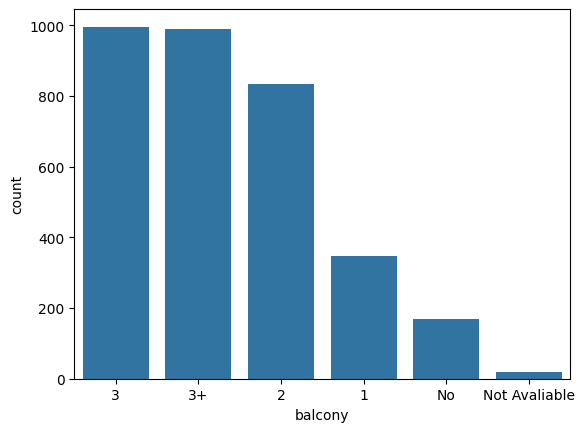

In [311]:
sns.barplot(next_dt['balcony'].value_counts())

### Super Built Up area

C:\Users\91959\AppData\Local\Temp\ipykernel_248\1924945442.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(next_dt['Super Built Up area'])


<Axes: xlabel='Super Built Up area', ylabel='Density'>

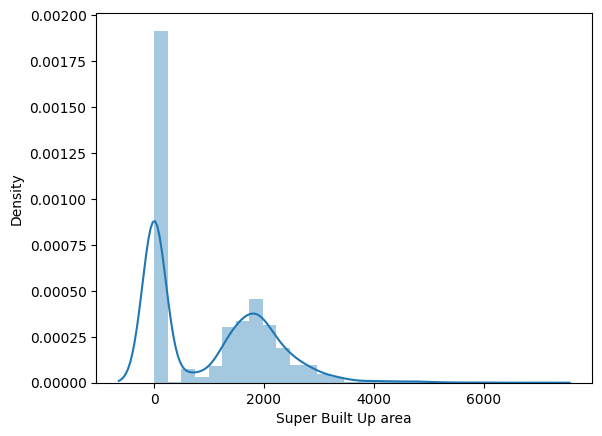

In [312]:
sns.distplot(next_dt['Super Built Up area'])

In [313]:
next_dt['Super Built Up area'].describe()

count    3355.000000
mean     1014.496268
std      1089.248669
min         0.000000
25%         0.000000
50%       925.050000
75%      1900.040000
max      6926.030000
Name: Super Built Up area, dtype: float64

### Built Up area

C:\Users\91959\AppData\Local\Temp\ipykernel_248\2752788952.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(next_dt['Built Up area'])


<Axes: xlabel='Built Up area', ylabel='Density'>

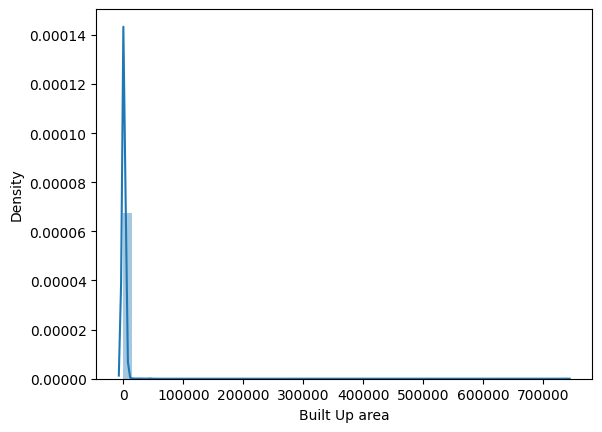

In [314]:
sns.distplot(next_dt['Built Up area'])

<Axes: xlabel='price', ylabel='Built Up area'>

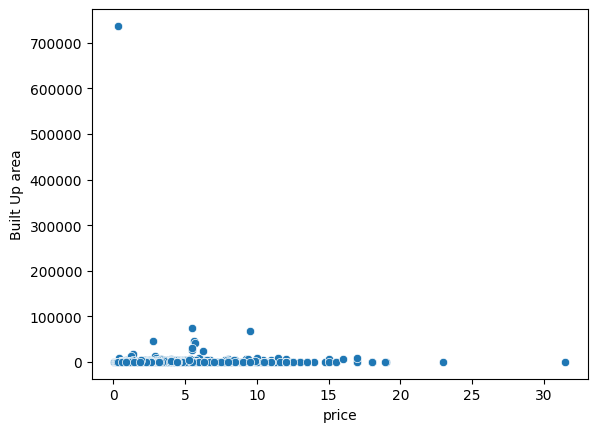

In [315]:
sns.scatterplot(next_dt , x='price' ,y='Built Up area')

In [316]:
next_dt['Built Up area'].describe()

count      3355.000000
mean        900.128075
std       12966.831441
min           0.000000
25%           0.000000
50%           0.000000
75%        1150.020000
max      737146.320000
Name: Built Up area, dtype: float64

In [317]:
next_dt = next_dt[next_dt['Built Up area']<=12000]

<Axes: xlabel='price', ylabel='Built Up area'>

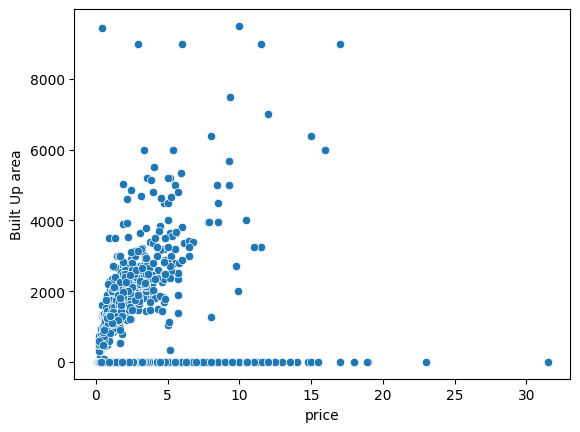

In [318]:
sns.scatterplot(next_dt, x='price' ,y='Built Up area')

### Plot area

C:\Users\91959\AppData\Local\Temp\ipykernel_248\4026229301.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(next_dt['Plot area'])


<Axes: xlabel='Plot area', ylabel='Density'>

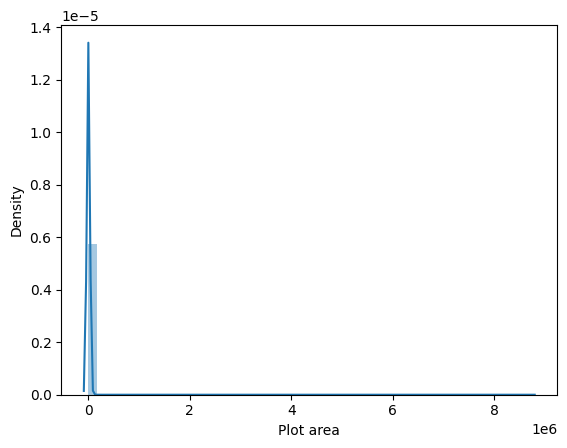

In [319]:
sns.distplot(next_dt['Plot area'])

In [320]:
next_dt['Built Up area'].describe()

count    3343.000000
mean      563.760302
std      1030.734957
min         0.000000
25%         0.000000
50%         0.000000
75%      1125.040000
max      9500.000000
Name: Built Up area, dtype: float64

### Carpet area

C:\Users\91959\AppData\Local\Temp\ipykernel_248\4268218405.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(next_dt['Carpet area'])


<Axes: xlabel='Carpet area', ylabel='Density'>

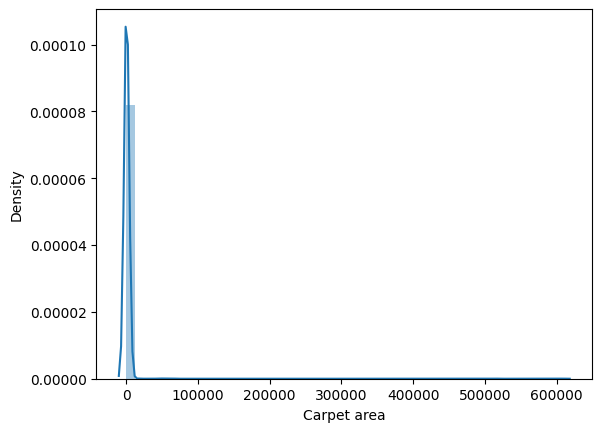

In [321]:
sns.distplot(next_dt['Carpet area'])

In [322]:
next_dt['Built Up area'].describe()

count    3343.000000
mean      563.760302
std      1030.734957
min         0.000000
25%         0.000000
50%         0.000000
75%      1125.040000
max      9500.000000
Name: Built Up area, dtype: float64

### Export File

<Axes: xlabel='price', ylabel='Built Up area'>

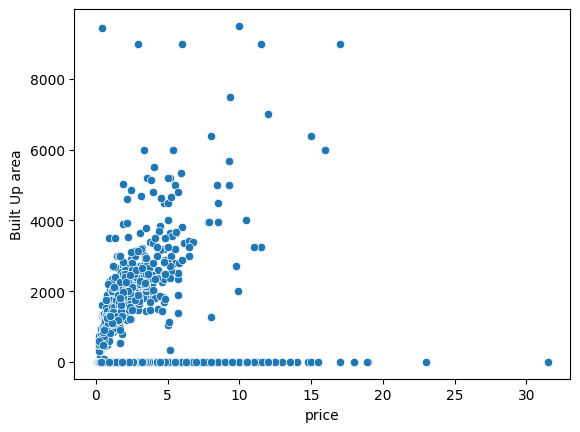

In [324]:
sns.scatterplot(next_dt , x='price' ,y='Built Up area')

In [323]:
next_dt.to_csv('Dataset/gurgaon_properties-outlier removed.csv',index=False)
print('successfull')

successfull
